## 1. Environment Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.linear_model import LogisticRegression
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
# RAdam recommended for VFL; fallback to Adam if unavailable (PyTorch >= 1.10 has RAdam)
try:
    from torch.optim import RAdam
except ImportError:
    RAdam = optim.Adam
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


## 2. Dataset Loading and Preprocessing

### 2.1 UCI Adult Dataset (32K Census Records)

In [2]:
def load_adult_dataset():
    """Load UCI Adult dataset for income prediction."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    columns = [
        'age', 'workclass', 'fnlwgt', 'education', 'education_num',
        'marital_status', 'occupation', 'relationship', 'race', 'sex',
        'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
    ]
    
    df = pd.read_csv(url, names=columns, sep=',\\s*', engine='python', na_values='?')
    df = df.dropna()
    
    # Encode target
    df['income'] = (df['income'] == '>50K').astype(int)
    
    # Encode categorical features
    categorical_cols = ['workclass', 'education', 'marital_status', 'occupation', 
                        'relationship', 'race', 'sex', 'native_country']
    
    for col in categorical_cols:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])
    
    X = df.drop('income', axis=1)
    y = df['income']
    
    return X, y

# Load dataset
X_adult, y_adult = load_adult_dataset()
print(f"UCI Adult Dataset: {X_adult.shape[0]} samples, {X_adult.shape[1]} features")
print(f"Class distribution: {y_adult.value_counts().to_dict()}")

UCI Adult Dataset: 30162 samples, 14 features
Class distribution: {0: 22654, 1: 7508}


### 2.2 German Credit Dataset (1K Records)

In [3]:
def load_german_credit_dataset():
    """Load German Credit dataset for credit risk assessment."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
    
    # Column names based on dataset documentation
    columns = [
        'checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
        'savings_status', 'employment', 'installment_rate', 'personal_status',
        'other_parties', 'residence_since', 'property_magnitude', 'age',
        'other_payment_plans', 'housing', 'existing_credits', 'job',
        'num_dependents', 'own_telephone', 'foreign_worker', 'class'
    ]
    
    df = pd.read_csv(url, names=columns, sep=' ')
    
    # Encode target (1 = Good, 2 = Bad) -> (1 = Good, 0 = Bad)
    df['class'] = (df['class'] == 1).astype(int)
    
    # Encode categorical features
    categorical_cols = ['checking_status', 'credit_history', 'purpose', 'savings_status',
                        'employment', 'personal_status', 'other_parties', 'property_magnitude',
                        'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']
    
    for col in categorical_cols:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
    
    X = df.drop('class', axis=1)
    y = df['class']
    
    return X, y

# Load dataset
X_german, y_german = load_german_credit_dataset()
print(f"German Credit Dataset: {X_german.shape[0]} samples, {X_german.shape[1]} features")
print(f"Class distribution: {y_german.value_counts().to_dict()}")


German Credit Dataset: 1000 samples, 20 features
Class distribution: {1: 700, 0: 300}


## 3. Vertical Federated Learning Data Partitioning

In VFL, different parties hold different features of the same samples.

In [4]:
class VFLDataPartitioner:
    """Partition data vertically for VFL simulation."""
    
    def __init__(self, X, y, n_parties=2, label_party=0, random_state=42):
        """
        Args:
            X: Feature DataFrame
            y: Labels
            n_parties: Number of parties
            label_party: Which party holds the labels (active party)
            random_state: Random seed for reproducibility
        """
        self.X = X
        self.y = y
        self.n_parties = n_parties
        self.label_party = label_party
        self.random_state = random_state
        
        self.feature_splits = None
        self.party_data = None
        
    def partition_features(self, method='equal', custom_splits=None):
        """
        Partition features among parties.
        
        Args:
            method: 'equal', 'random', or 'custom'
            custom_splits: List of feature lists for each party
        """
        np.random.seed(self.random_state)
        all_features = list(self.X.columns)
        
        if method == 'custom' and custom_splits is not None:
            self.feature_splits = custom_splits
        elif method == 'equal':
            np.random.shuffle(all_features)
            split_size = len(all_features) // self.n_parties
            self.feature_splits = []
            for i in range(self.n_parties):
                start = i * split_size
                if i == self.n_parties - 1:
                    self.feature_splits.append(all_features[start:])
                else:
                    self.feature_splits.append(all_features[start:start + split_size])
        elif method == 'random':
            # Random assignment with overlap prevention
            np.random.shuffle(all_features)
            sizes = np.random.dirichlet(np.ones(self.n_parties)) * len(all_features)
            sizes = np.round(sizes).astype(int)
            sizes[-1] = len(all_features) - sum(sizes[:-1])
            
            self.feature_splits = []
            start = 0
            for size in sizes:
                self.feature_splits.append(all_features[start:start + int(size)])
                start += int(size)
        
        # Create party data
        self.party_data = []
        for i in range(self.n_parties):
            party_X = self.X[self.feature_splits[i]]
            party_y = self.y if i == self.label_party else None
            self.party_data.append({
                'X': party_X,
                'y': party_y,
                'features': self.feature_splits[i],
                'is_active': i == self.label_party
            })
            
        return self.party_data
    
    def get_party_data(self, party_id):
        """Get data for a specific party."""
        return self.party_data[party_id]
    
    def summary(self):
        """Print partition summary."""
        print("VFL Data Partition Summary")
        print("=" * 50)
        for i, party in enumerate(self.party_data):
            party_type = "Active (has labels)" if party['is_active'] else "Passive"
            print(f"Party {i} [{party_type}]:")
            print(f"  Features: {len(party['features'])}")
            print(f"  Feature names: {party['features'][:5]}..." if len(party['features']) > 5 else f"  Feature names: {party['features']}")
        print("=" * 50)


In [5]:
partitioner_adult = VFLDataPartitioner(X_adult, y_adult, n_parties=4, label_party=0)
adult_parties = partitioner_adult.partition_features(method='equal')
partitioner_adult.summary()

VFL Data Partition Summary
Party 0 [Active (has labels)]:
  Features: 3
  Feature names: ['sex', 'capital_loss', 'age']
Party 1 [Passive]:
  Features: 3
  Feature names: ['hours_per_week', 'marital_status', 'race']
Party 2 [Passive]:
  Features: 3
  Feature names: ['fnlwgt', 'workclass', 'native_country']
Party 3 [Passive]:
  Features: 5
  Feature names: ['education_num', 'relationship', 'capital_gain', 'education', 'occupation']


In [6]:
partitioner_german = VFLDataPartitioner(X_german, y_german, n_parties=4, label_party=0)
german_parties = partitioner_german.partition_features(method='equal')
partitioner_german.summary()

VFL Data Partition Summary
Party 0 [Active (has labels)]:
  Features: 5
  Feature names: ['checking_status', 'num_dependents', 'existing_credits', 'duration', 'personal_status']
Party 1 [Passive]:
  Features: 5
  Feature names: ['savings_status', 'property_magnitude', 'purpose', 'own_telephone', 'job']
Party 2 [Passive]:
  Features: 5
  Feature names: ['other_payment_plans', 'credit_history', 'other_parties', 'foreign_worker', 'credit_amount']
Party 3 [Passive]:
  Features: 5
  Feature names: ['age', 'installment_rate', 'residence_since', 'housing', 'employment']


## 4. VFL Model Architecture

Split learning architecture where each party has a bottom model and the active party has the top model.

In [7]:
class BottomModel(nn.Module):
    """Bottom (passive) model. Tabular: single hidden layer, 8 neurons."""
    
    def __init__(self, input_dim, hidden_dim=8, output_dim=32):
        super(BottomModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
            nn.ReLU()
        )
        
    def forward(self, x):
        return self.network(x)


class TopModel(nn.Module):
    """Top (active) model. Tabular: single hidden layer 32 neurons + output layer."""
    
    def __init__(self, input_dim, hidden_dim=32, output_dim=1):
        super(TopModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        return self.network(x)


In [8]:
class VFLModel:
    """Vertical Federated Learning Model with Split Learning."""
    
    def __init__(self, party_data, embedding_dim=32, hidden_dim_bottom=8, hidden_dim_top=32, device='cpu'):
        self.party_data = party_data
        self.n_parties = len(party_data)
        self.device = device
        self.embedding_dim = embedding_dim
        
        # Passive (tabular): single hidden layer, 8 neurons
        self.bottom_models = []
        for party in party_data:
            input_dim = len(party['features'])
            model = BottomModel(input_dim, hidden_dim_bottom, embedding_dim).to(device)
            self.bottom_models.append(model)
        
        # Active (tabular): single hidden layer 32 neurons + output
        top_input_dim = embedding_dim * self.n_parties
        self.top_model = TopModel(top_input_dim, hidden_dim_top, 1).to(device)
        
        # Store gradients for unlearning
        self.gradient_history = []
        
    def forward(self, X_parties):
        """Forward pass through all bottom models and top model."""
        embeddings = []
        for i, (model, X) in enumerate(zip(self.bottom_models, X_parties)):
            emb = model(X)
            embeddings.append(emb)
        
        # Concatenate embeddings
        combined = torch.cat(embeddings, dim=1)
        output = self.top_model(combined)
        return output, embeddings
    
    def get_all_parameters(self):
        """Get all trainable parameters."""
        params = []
        for model in self.bottom_models:
            params.extend(list(model.parameters()))
        params.extend(list(self.top_model.parameters()))
        return params
    
    def state_dict(self):
        """Get state dictionary for all models (for saving/loading)."""
        state = {
            'top_model': self.top_model.state_dict(),
            'bottom_models': [m.state_dict() for m in self.bottom_models]
        }
        return state
    
    def load_state_dict(self, state):
        """Load state dictionary into all models."""
        self.top_model.load_state_dict(state['top_model'])
        for i, m_state in enumerate(state['bottom_models']):
            self.bottom_models[i].load_state_dict(m_state)


## 5. VFL Training Framework

In [9]:
class VFLTrainer:
    """Trainer for Vertical Federated Learning with unlearning support."""

    def __init__(self, vfl_model, learning_rate=0.01):
        self.model = vfl_model
        self.criterion = nn.BCELoss()
        self.optimizer = RAdam(self.model.get_all_parameters(), lr=learning_rate)

        # Training history for unlearning
        self.training_history = []
        self.party_data = vfl_model.party_data

    def prepare_data(self, party_data, test_size=0.2):
        """Prepare data loaders for training."""
        # Get data from each party
        X_list = [party['X'].values.astype(np.float32) for party in party_data]

        # Get labels from active party
        y = None
        for party in party_data:
            if party['is_active']:
                y = party['y'].values.astype(np.float32)
                break

        # Normalize features
        scalers = []
        X_scaled = []
        for X in X_list:
            scaler = StandardScaler()
            X_scaled.append(scaler.fit_transform(X))
            scalers.append(scaler)

        # Train-test split (same indices for all parties)
        indices = np.arange(len(y))
        train_idx, test_idx = train_test_split(indices, test_size=test_size, random_state=42)

        self.train_idx = train_idx
        self.test_idx = test_idx

        # Create tensors
        X_train = [torch.FloatTensor(X[train_idx]).to(self.model.device) for X in X_scaled]
        X_test = [torch.FloatTensor(X[test_idx]).to(self.model.device) for X in X_scaled]
        y_train = torch.FloatTensor(y[train_idx]).unsqueeze(1).to(self.model.device)
        y_test = torch.FloatTensor(y[test_idx]).unsqueeze(1).to(self.model.device)

        return X_train, X_test, y_train, y_test, scalers

    def train_epoch(self, X_train, y_train, batch_size=512):
        """Train for one epoch."""
        n_samples = y_train.shape[0]
        indices = np.random.permutation(n_samples)

        total_loss = 0
        n_batches = 0

        for model in self.model.bottom_models:
            model.train()
        self.model.top_model.train()

        for start in range(0, n_samples, batch_size):
            end = min(start + batch_size, n_samples)
            batch_idx = indices[start:end]

            # Get batch data for each party
            X_batch = [X[batch_idx] for X in X_train]
            y_batch = y_train[batch_idx]

            # Forward pass
            self.optimizer.zero_grad()
            output, _ = self.model.forward(X_batch)
            loss = self.criterion(output, y_batch)

            # Backward pass
            loss.backward()
            self.optimizer.step()

            total_loss += loss.item()
            n_batches += 1

        return total_loss / n_batches

    def evaluate(self, X_test, y_test):
        """Evaluate the model."""
        for model in self.model.bottom_models:
            model.eval()
        self.model.top_model.eval()

        with torch.no_grad():
            output, _ = self.model.forward(X_test)
            predictions = (output > 0.5).float()

            y_true = y_test.cpu().numpy()
            y_pred = predictions.cpu().numpy()
            y_prob = output.cpu().numpy()

            acc = accuracy_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred)
            auc = roc_auc_score(y_true, y_prob)

        return {'accuracy': acc, 'f1': f1, 'auc': auc}

    def train(self, X_train, X_test, y_train, y_test, epochs=50, batch_size=512, verbose=True):
        """Full training loop."""
        history = {'train_loss': [], 'val_acc': [], 'val_f1': [], 'val_auc': []}

        for epoch in range(epochs):
            loss = self.train_epoch(X_train, y_train, batch_size)
            metrics = self.evaluate(X_test, y_test)

            history['train_loss'].append(loss)
            history['val_acc'].append(metrics['accuracy'])
            history['val_f1'].append(metrics['f1'])
            history['val_auc'].append(metrics['auc'])

            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{epochs} - Loss: {loss:.4f} - "
                      f"Acc: {metrics['accuracy']:.4f} - F1: {metrics['f1']:.4f} - AUC: {metrics['auc']:.4f}")

        self.training_history = history
        return history

    def train_with_embedding_history(self, X_train, X_test, y_train, y_test, epochs=50, batch_size=512,
                                      lr_active=0.01, lr_passive=0.01, verbose=True):
        """
        VFL training with historical embedding storage (Algorithm: VFL Training).
        η_1 = lr_active for active (top) model, η_2 = lr_passive for passive (bottom) models.
        Stores E_i^t for each epoch t and party i. Returns history and historical_embeddings.
        """
        top_params = list(self.model.top_model.parameters())
        bottom_params = []
        for m in self.model.bottom_models:
            bottom_params.extend(list(m.parameters()))
        self.optimizer = RAdam([
            {'params': top_params, 'lr': lr_active},
            {'params': bottom_params, 'lr': lr_passive}
        ])

        history = {'train_loss': [], 'val_acc': [], 'val_f1': [], 'val_auc': []}
        historical_embeddings = []
        n_train = y_train.shape[0]
        k = self.model.n_parties

        for epoch in range(epochs):
            loss = self.train_epoch(X_train, y_train, batch_size)
            metrics = self.evaluate(X_test, y_test)
            history['train_loss'].append(loss)
            history['val_acc'].append(metrics['accuracy'])
            history['val_f1'].append(metrics['f1'])
            history['val_auc'].append(metrics['auc'])

            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{epochs} - Loss: {loss:.4f} - "
                      f"Acc: {metrics['accuracy']:.4f} - F1: {metrics['f1']:.4f} - AUC: {metrics['auc']:.4f}")

            for m in self.model.bottom_models:
                m.eval()
            self.model.top_model.eval()
            emb_list = [[] for _ in range(k)]
            with torch.no_grad():
                for start in range(0, n_train, batch_size):
                    end = min(start + batch_size, n_train)
                    X_batch = [X[start:end] for X in X_train]
                    _, embeddings = self.model.forward(X_batch)
                    for i in range(k):
                        emb_list[i].append(embeddings[i].cpu())
            E_t = [torch.cat(emb_list[i], dim=0).to(self.model.device) for i in range(k)]
            historical_embeddings.append(E_t)

        self.training_history = history
        self.historical_embeddings = historical_embeddings
        return history, historical_embeddings

Train samples: 24129, Test samples: 6033

Training VFL model (with embedding history)...
Epoch 10/50 - Loss: 0.3241 - Acc: 0.8455 - F1: 0.6830 - AUC: 0.9081
Epoch 20/50 - Loss: 0.3155 - Acc: 0.8507 - F1: 0.7031 - AUC: 0.9108
Epoch 30/50 - Loss: 0.3056 - Acc: 0.8538 - F1: 0.6883 - AUC: 0.9115
Epoch 40/50 - Loss: 0.3009 - Acc: 0.8546 - F1: 0.7036 - AUC: 0.9118
Epoch 50/50 - Loss: 0.2990 - Acc: 0.8533 - F1: 0.6928 - AUC: 0.9081
Stored historical embeddings for 50 epochs, 4 parties.

Final Test Set Metrics
Accuracy: 0.8533
F1 Score: 0.6928
ROC-AUC:  0.9081


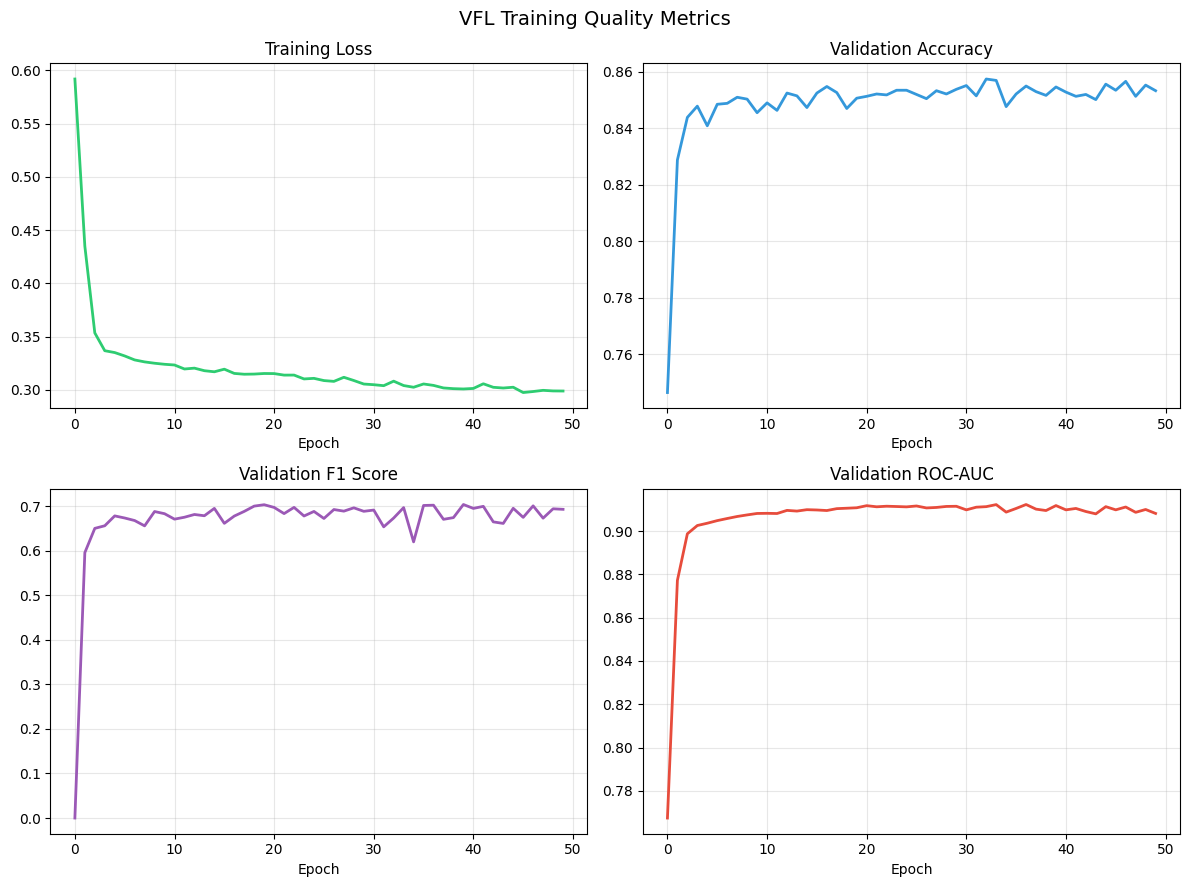

In [10]:
# Train VFL framework on Adult dataset
EPOCHS = 50
BATCH_SIZE = 512  # preferred for VFL (communication-intensive)
LR = 1e-2         # 1e-2 for tabular, 1e-3 for image

# Build VFL model and trainer (passive 8 neurons, active 32 neurons)
vfl_model_adult = VFLModel(adult_parties, embedding_dim=32, device=device)
trainer_adult = VFLTrainer(vfl_model_adult, learning_rate=LR)

# Prepare data (train/test split, scaling)
X_train, X_test, y_train, y_test, scalers = trainer_adult.prepare_data(adult_parties, test_size=0.2)
print(f"Train samples: {y_train.shape[0]}, Test samples: {y_test.shape[0]}")

# Train with historical embedding storage (for VFU-KD unlearning)
print("\nTraining VFL model (with embedding history)...")
LR_ACTIVE, LR_PASSIVE = 1e-2, 1e-2  # η_1, η_2 (tabular)
history, historical_embeddings = trainer_adult.train_with_embedding_history(
    X_train, X_test, y_train, y_test,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    lr_active=LR_ACTIVE, lr_passive=LR_PASSIVE, verbose=True
)
print(f"Stored historical embeddings for {len(historical_embeddings)} epochs, {len(historical_embeddings[0])} parties.")

# Final evaluation metrics
final_metrics = trainer_adult.evaluate(X_test, y_test)
print("\n" + "=" * 50)
print("Final Test Set Metrics")
print("=" * 50)
print(f"Accuracy: {final_metrics['accuracy']:.4f}")
print(f"F1 Score: {final_metrics['f1']:.4f}")
print(f"ROC-AUC:  {final_metrics['auc']:.4f}")
print("=" * 50)

# Plot training quality metrics
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("VFL Training Quality Metrics", fontsize=14)

axes[0, 0].plot(history['train_loss'], color='#2ecc71', linewidth=2)
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(history['val_acc'], color='#3498db', linewidth=2)
axes[0, 1].set_title("Validation Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(history['val_f1'], color='#9b59b6', linewidth=2)
axes[1, 0].set_title("Validation F1 Score")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(history['val_auc'], color='#e74c3c', linewidth=2)
axes[1, 1].set_title("Validation ROC-AUC")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Unlearning Algorithms  

Algorithm 1: VFU-KD — Passive Party Unlearning :  
Unlearn passive party P_u by training a new active model θ_a' (input size (k-1)×embedding_dim) on historical embeddings without P_u, using prediction loss + knowledge distillation from the original (teacher) active model.

In [11]:
import torch.nn.functional as F

def vfu_kd_passive_unlearn(vfl_model, historical_embeddings, y_train, passive_party_u,
                           lr_unlearn=0.01, lambda_distill=0.3, unlearn_epochs=30, device='cpu', verbose=True):
    """
    VFU-KD Passive Party Unlearning.
    Input: passive party index P_u (0-based), historical embeddings E_i^s for all s, all i.
    Output: unlearned active model θ_a' (student) and unlearn history.
    """
    k = vfl_model.n_parties
    emb_dim = vfl_model.embedding_dim
    if passive_party_u < 0 or passive_party_u >= k:
        raise ValueError("passive_party_u must be in [0, k-1]")
    if vfl_model.party_data[passive_party_u]['is_active']:
        raise ValueError("Cannot unlearn the active party (label holder). Target must be a passive party.")

    # 1. Student: new top model with input (k-1)*embedding_dim (remove P_u's slot)
    retained_input_dim = (k - 1) * emb_dim
    student_top = TopModel(retained_input_dim, hidden_dim=32, output_dim=1).to(device)

    # 2. Teacher: current active model (frozen)
    teacher_top = vfl_model.top_model
    for p in teacher_top.parameters():
        p.requires_grad = False

    optimizer = RAdam(student_top.parameters(), lr=lr_unlearn)
    criterion_bce = nn.BCELoss()
    T = len(historical_embeddings)
    n_train = y_train.shape[0]

    history = {'loss': [], 'l_pred': [], 'l_dist': []}

    for e in range(unlearn_epochs):
        student_top.train()
        epoch_loss, epoch_pred, epoch_dist = 0.0, 0.0, 0.0
        n_steps = 0

        for s in range(T):
            # E_retain^s = [E_0^s, ..., E_{u-1}^s, E_{u+1}^s, ..., E_{k-1}^s]
            E_s = historical_embeddings[s]
            E_retain = torch.cat([E_s[i] for i in range(k) if i != passive_party_u], dim=1)
            E_full = torch.cat(E_s, dim=1)

            with torch.no_grad():
                y_teacher = teacher_top(E_full)

            y_student = student_top(E_retain)
            eps = 1e-7
            y_s = y_student.clamp(eps, 1 - eps)
            y_t = y_teacher.clamp(eps, 1 - eps)
            # Binary KL: 2-class probs [1-p, p]
            log_p_s = torch.stack([torch.log(1 - y_s), torch.log(y_s)], dim=1)
            p_t = torch.stack([1 - y_t, y_t], dim=1)
            L_pred = criterion_bce(y_student, y_train)
            L_dist = F.kl_div(log_p_s, p_t, reduction='batchmean')
            L = (1 - lambda_distill) * L_pred + lambda_distill * L_dist

            optimizer.zero_grad()
            L.backward()
            optimizer.step()

            epoch_loss += L.item()
            epoch_pred += L_pred.item()
            epoch_dist += L_dist.item()
            n_steps += 1

        history['loss'].append(epoch_loss / n_steps)
        history['l_pred'].append(epoch_pred / n_steps)
        history['l_dist'].append(epoch_dist / n_steps)
        if verbose and (e + 1) % 10 == 0:
            print(f"Unlearn Epoch {e+1}/{unlearn_epochs} - Loss: {history['loss'][-1]:.4f} "
                  f"(L_pred: {history['l_pred'][-1]:.4f}, L_dist: {history['l_dist'][-1]:.4f})")

    return student_top, history


def evaluate_unlearned_model(vfl_model, student_top, X_test_list_by_party, y_test, passive_party_u, device):
    """Evaluate model after unlearning: use retained bottom models + student top (no P_u)."""
    k = vfl_model.n_parties
    retained_parties = [i for i in range(k) if i != passive_party_u]
    for m in vfl_model.bottom_models:
        m.eval()
    student_top.eval()
    with torch.no_grad():
        embeddings_retain = []
        for i in retained_parties:
            emb = vfl_model.bottom_models[i](X_test_list_by_party[i])
            embeddings_retain.append(emb)
        combined = torch.cat(embeddings_retain, dim=1)
        output = student_top(combined)
        pred = (output > 0.5).float()
    y_true = y_test.cpu().numpy()
    y_pred = pred.cpu().numpy()
    y_prob = output.cpu().numpy()
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'auc': roc_auc_score(y_true, y_prob)
    }

In [12]:
# Run VFU-KD unlearning: remove passive party P_1 (index 1)
PASSIVE_PARTY_TO_UNLEARN = 1  # P_u
ETA_1 = 1e-2    # η_1 (tabular)
LAMBDA_DISTILL = 0.3  # λ (distillation weight, set to 0.3 in experiments)
UNLEARN_EPOCHS = 30

student_top, unlearn_history = vfu_kd_passive_unlearn(
    vfl_model_adult, trainer_adult.historical_embeddings, y_train,
    passive_party_u=PASSIVE_PARTY_TO_UNLEARN,
    lr_unlearn=ETA_1, lambda_distill=LAMBDA_DISTILL, unlearn_epochs=UNLEARN_EPOCHS,
    device=device, verbose=True
)

# Metrics: before (full model) vs after (unlearned model without P_u)
metrics_before = trainer_adult.evaluate(X_test, y_test)
metrics_after = evaluate_unlearned_model(
    vfl_model_adult, student_top, X_test, y_test,
    passive_party_u=PASSIVE_PARTY_TO_UNLEARN, device=device
)

print("\n" + "=" * 60)
print("UNLEARNING QUALITY METRICS")
print("=" * 60)
print(f"{'Metric':<12} {'Before (full)':<18} {'After (no P_u)':<18} {'Δ':<10}")
print("-" * 60)
for key in ['accuracy', 'f1', 'auc']:
    b, a = metrics_before[key], metrics_after[key]
    delta = a - b
    print(f"{key:<12} {b:<18.4f} {a:<18.4f} {delta:+.4f}")
print("=" * 60)
print("(After = model with passive party P_u removed; small Δ indicates good retention.)")

Unlearn Epoch 10/30 - Loss: 0.2586 (L_pred: 0.3503, L_dist: 0.0448)
Unlearn Epoch 20/30 - Loss: 0.2538 (L_pred: 0.3455, L_dist: 0.0396)
Unlearn Epoch 30/30 - Loss: 0.2487 (L_pred: 0.3402, L_dist: 0.0354)

UNLEARNING QUALITY METRICS
Metric       Before (full)      After (no P_u)     Δ         
------------------------------------------------------------
accuracy     0.8533             0.8487             -0.0046
f1           0.6928             0.6813             -0.0115
auc          0.9081             0.9010             -0.0071
(After = model with passive party P_u removed; small Δ indicates good retention.)


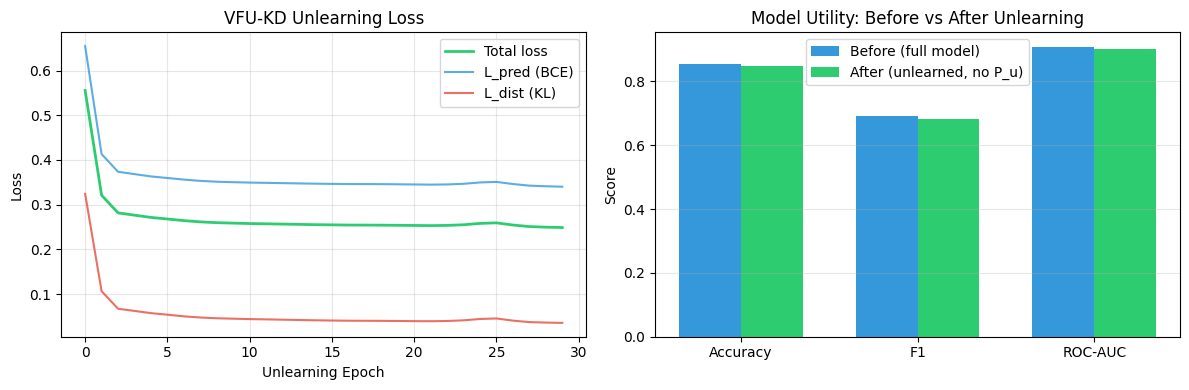

In [13]:
# Unlearning quality: loss curves and before/after comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: unlearning loss over epochs
axes[0].plot(unlearn_history['loss'], label='Total loss', color='#2ecc71', linewidth=2)
axes[0].plot(unlearn_history['l_pred'], label='L_pred (BCE)', color='#3498db', alpha=0.8)
axes[0].plot(unlearn_history['l_dist'], label='L_dist (KL)', color='#e74c3c', alpha=0.8)
axes[0].set_xlabel("Unlearning Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("VFU-KD Unlearning Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Right: before vs after metrics
metrics_names = ['accuracy', 'f1', 'auc']
before_vals = [metrics_before[k] for k in metrics_names]
after_vals = [metrics_after[k] for k in metrics_names]
x = np.arange(len(metrics_names))
w = 0.35
axes[1].bar(x - w/2, before_vals, w, label='Before (full model)', color='#3498db')
axes[1].bar(x + w/2, after_vals, w, label='After (unlearned, no P_u)', color='#2ecc71')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['Accuracy', 'F1', 'ROC-AUC'])
axes[1].set_ylabel("Score")
axes[1].set_title("Model Utility: Before vs After Unlearning")
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

Algorithm 2: VFU-KD — Feature Unlearning (Passive Party Side)

When passive party P_u wants to remove specific features F_u from its local model: train a student bottom model θ_u' with reduced input (without F_u) by distilling embeddings from the teacher θ_u. No labels and no communication with the active party.

In [14]:
def vfu_kd_feature_unlearn(vfl_model, X_party_u_full, feature_indices_to_forget, passive_party_u,
                           lr=0.01, unlearn_epochs=30, batch_size=512, device='cpu', verbose=True):
    """
    VFU-KD Feature Unlearning (Passive Party Side).
    P_u removes features F_u; student θ_u' has input_size = |features_P_u| - |F_u|.
    Teacher = θ_u (frozen), student = θ_u'. Loss = KL(e_S || e_T) on embeddings.
    """
    if vfl_model.party_data[passive_party_u]['is_active']:
        raise ValueError("Cannot unlearn features from the active party. Target must be a passive party.")
    teacher = vfl_model.bottom_models[passive_party_u]
    full_dim = X_party_u_full.shape[1]
    feature_indices_to_forget = sorted(set(feature_indices_to_forget))
    retained_idx = [i for i in range(full_dim) if i not in feature_indices_to_forget]
    reduced_dim = len(retained_idx)

    # 1. Student: reduced input dimension
    student_bottom = BottomModel(reduced_dim, hidden_dim=8, output_dim=vfl_model.embedding_dim).to(device)

    # 2. Teacher frozen
    for p in teacher.parameters():
        p.requires_grad = False

    # D_reduced: exclude F_u columns
    X_reduced = X_party_u_full[:, retained_idx]

    optimizer = RAdam(student_bottom.parameters(), lr=lr)
    n_train = X_party_u_full.shape[0]
    history = {'loss': []}

    for e in range(unlearn_epochs):
        student_bottom.train()
        perm = np.random.permutation(n_train)
        epoch_loss, n_batches = 0.0, 0

        for start in range(0, n_train, batch_size):
            end = min(start + batch_size, n_train)
            idx = perm[start:end]
            D_full = X_party_u_full[idx]
            D_reduced = X_reduced[idx]

            with torch.no_grad():
                e_T = teacher(D_full)
            e_S = student_bottom(D_reduced)

            # KL on embeddings: treat as distributions via softmax over embedding dim
            log_e_S = F.log_softmax(e_S, dim=1)
            p_T = F.softmax(e_T, dim=1)
            L = F.kl_div(log_e_S, p_T, reduction='batchmean')

            optimizer.zero_grad()
            L.backward()
            optimizer.step()

            epoch_loss += L.item()
            n_batches += 1

        history['loss'].append(epoch_loss / n_batches)
        if verbose and (e + 1) % 10 == 0:
            print(f"Feature Unlearn Epoch {e+1}/{unlearn_epochs} - KL loss: {history['loss'][-1]:.4f}")

    return student_bottom, history, retained_idx


def evaluate_vfl_with_party_bottom_replaced(vfl_model, X_test_per_party, y_test, replace_party_id,
                                            replacement_bottom, replace_party_tensor, device):
    """Evaluate full VFL when one party's bottom is replaced and that party uses a different input tensor."""
    for m in vfl_model.bottom_models:
        m.eval()
    replacement_bottom.eval()
    vfl_model.top_model.eval()

    with torch.no_grad():
        embeddings = []
        for i in range(vfl_model.n_parties):
            if i == replace_party_id:
                emb = replacement_bottom(replace_party_tensor)
            else:
                emb = vfl_model.bottom_models[i](X_test_per_party[i])
            embeddings.append(emb)
        combined = torch.cat(embeddings, dim=1)
        output = vfl_model.top_model(combined)
        pred = (output > 0.5).float()

    y_true = y_test.cpu().numpy()
    y_pred = pred.cpu().numpy()
    y_prob = output.cpu().numpy()
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'auc': roc_auc_score(y_true, y_prob)
    }

In [15]:
# Run VFU-KD Feature Unlearning: P_u removes features F_u
PASSIVE_PARTY_U = 1           # target passive party (0 = active, 1/2/3 = passive)
FEATURE_INDICES_TO_FORGET = [0, 1]  # indices of features to remove from P_u's input (e.g. first 2)
ETA_2 = 1e-2                   # η_2 (tabular)
FEATURE_UNLEARN_EPOCHS = 30

X_party_u_full = X_train[PASSIVE_PARTY_U]
student_bottom_u, feat_unlearn_history, retained_idx = vfu_kd_feature_unlearn(
    vfl_model_adult, X_party_u_full, FEATURE_INDICES_TO_FORGET, PASSIVE_PARTY_U,
    lr=ETA_2, unlearn_epochs=FEATURE_UNLEARN_EPOCHS, batch_size=512, device=device, verbose=True
)

# Build test set with reduced features for P_u (to use with student bottom)
X_test_reduced_u = X_test[PASSIVE_PARTY_U][:, retained_idx]

# Metrics: before (original) vs after (P_u uses student bottom with reduced features)
metrics_before_feat = trainer_adult.evaluate(X_test, y_test)
metrics_after_feat = evaluate_vfl_with_party_bottom_replaced(
    vfl_model_adult, X_test, y_test, PASSIVE_PARTY_U, student_bottom_u, X_test_reduced_u, device
)

print("\n" + "=" * 60)
print("FEATURE UNLEARNING QUALITY METRICS (Passive Party P_u, features F_u removed)")
print("=" * 60)
print(f"Party P_{PASSIVE_PARTY_U} forgot {len(FEATURE_INDICES_TO_FORGET)} feature(s); "
      f"input dim: {X_party_u_full.shape[1]} → {len(retained_idx)}")
print(f"{'Metric':<12} {'Before (full)':<18} {'After (P_u reduced)':<22} {'Δ':<10}")
print("-" * 60)
for key in ['accuracy', 'f1', 'auc']:
    b, a = metrics_before_feat[key], metrics_after_feat[key]
    delta = a - b
    print(f"{key:<12} {b:<18.4f} {a:<22.4f} {delta:+.4f}")
print("=" * 60)

Feature Unlearn Epoch 10/30 - KL loss: 0.0436
Feature Unlearn Epoch 20/30 - KL loss: 0.0434
Feature Unlearn Epoch 30/30 - KL loss: 0.0435

FEATURE UNLEARNING QUALITY METRICS (Passive Party P_u, features F_u removed)
Party P_1 forgot 2 feature(s); input dim: 3 → 1
Metric       Before (full)      After (P_u reduced)    Δ         
------------------------------------------------------------
accuracy     0.8533             0.8233                 -0.0300
f1           0.6928             0.5702                 -0.1227
auc          0.9081             0.8645                 -0.0437


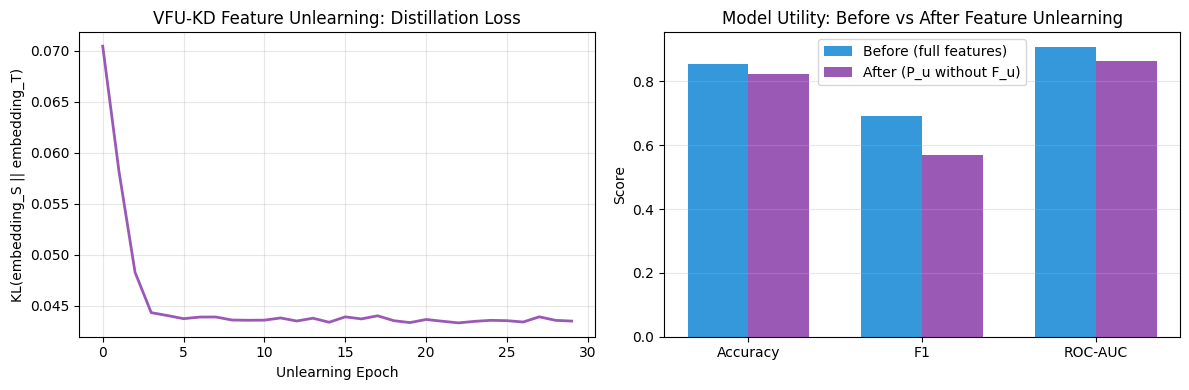

In [16]:
# Feature unlearning: distillation loss curve and before/after comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(feat_unlearn_history['loss'], color='#9b59b6', linewidth=2)
axes[0].set_xlabel("Unlearning Epoch")
axes[0].set_ylabel("KL(embedding_S || embedding_T)")
axes[0].set_title("VFU-KD Feature Unlearning: Distillation Loss")
axes[0].grid(True, alpha=0.3)

metrics_names = ['accuracy', 'f1', 'auc']
before_vals = [metrics_before_feat[k] for k in metrics_names]
after_vals = [metrics_after_feat[k] for k in metrics_names]
x = np.arange(len(metrics_names))
w = 0.35
axes[1].bar(x - w/2, before_vals, w, label='Before (full features)', color='#3498db')
axes[1].bar(x + w/2, after_vals, w, label='After (P_u without F_u)', color='#9b59b6')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['Accuracy', 'F1', 'ROC-AUC'])
axes[1].set_ylabel("Score")
axes[1].set_title("Model Utility: Before vs After Feature Unlearning")
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

Algorithm 3: VFU-GA — Sample Unlearning

When the active party needs to forget a specific set of samples B_u: gradient ascent on forget loss L_f and descent on retain loss L_r. Update: θ_a ← θ_a - η_1 ∇L_r + α ∇L_f. Uses stored embeddings (no bottom model re-computation).

In [17]:
def vfu_ga_sample_unlearn(vfl_model, historical_embeddings, y_train, batch_ids_to_unlearn,
                          lr=0.01, alpha=0.1, unlearn_epochs=5, device='cpu', verbose=True):
    """
    VFU-GA Sample Unlearning.
    Input: Target batch IDs B_u (sample indices to unlearn), η_1 (lr), α (unlearning rate), E_u (unlearn_epochs).
    Update: θ_a ← θ_a - η_1 * ∇L_r + α * ∇L_f  (implemented as minimize L_r - (α/η_1)*L_f with lr=η_1).
    Modifies θ_a in place; returns history (L_f, L_r).
    """
    B_u = np.array(sorted(set(batch_ids_to_unlearn)))
    n_train = y_train.shape[0]
    retain_idx = np.array([i for i in range(n_train) if i not in set(B_u)])

    if len(B_u) == 0:
        raise ValueError("batch_ids_to_unlearn must be non-empty")
    if len(retain_idx) == 0:
        raise ValueError("Retain set cannot be empty")

    # Stored embeddings from last epoch: E = [E_1^T, ..., E_k^T] concatenated
    last_epoch = historical_embeddings[-1]
    E = torch.cat(last_epoch, dim=1).to(device)  # (n_train, k*emb_dim)
    E_forget = E[B_u]
    E_retain = E[retain_idx]
    y_forget = y_train[B_u]
    y_retain = y_train[retain_idx]

    top_model = vfl_model.top_model
    # Ensure top model is trainable (may have been frozen by a previous unlearning step)
    for p in top_model.parameters():
        p.requires_grad = True
    optimizer = RAdam(top_model.parameters(), lr=lr)
    criterion = nn.BCELoss()
    k_ga = alpha / lr  # coefficient for L_f in combined loss: minimize L_r - k_ga*L_f

    history = {'L_f': [], 'L_r': []}

    for e in range(unlearn_epochs):
        top_model.train()
        y_hat_forget = top_model(E_forget)
        y_hat_retain = top_model(E_retain)
        L_f = criterion(y_hat_forget, y_forget)
        L_r = criterion(y_hat_retain, y_retain)
        loss = L_r - k_ga * L_f  # gradient descent on this = -∇L_r + (α/η_1)*∇L_f; then step with η_1

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        history['L_f'].append(L_f.item())
        history['L_r'].append(L_r.item())
        if verbose and (e + 1) % 10 == 0:
            print(f"Sample Unlearn Epoch {e+1}/{unlearn_epochs} - L_f: {history['L_f'][-1]:.4f}, L_r: {history['L_r'][-1]:.4f}")

    return history


def evaluate_on_embeddings(vfl_model, E_tensor, y_tensor, device):
    """Evaluate top model on given concatenated embeddings and labels."""
    vfl_model.top_model.eval()
    with torch.no_grad():
        out = vfl_model.top_model(E_tensor)
        pred = (out > 0.5).float()
    y_true = y_tensor.cpu().numpy()
    y_pred = pred.cpu().numpy()
    y_prob = out.cpu().numpy()
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'auc': roc_auc_score(y_true, y_prob)
    }

In [18]:
# VFU-GA Sample Unlearning: choose samples B_u to forget
N_FORGET = 500  # number of training samples to unlearn
np.random.seed(123)
B_U = np.random.choice(len(y_train), size=min(N_FORGET, len(y_train)), replace=False).tolist()

# Stored embeddings (last epoch) for forget/retain evaluation
last_emb = historical_embeddings[-1]
E_full = torch.cat(last_emb, dim=1).to(device)
retain_idx = np.array([i for i in range(len(y_train)) if i not in set(B_U)])
E_forget = E_full[B_U]
E_retain = E_full[retain_idx]
y_forget = y_train[B_U]
y_retain = y_train[retain_idx]

# Metrics BEFORE unlearning (on forget set, retain set, and test set)
forget_metrics_before = evaluate_on_embeddings(vfl_model_adult, E_forget, y_forget, device)
retain_metrics_before = evaluate_on_embeddings(vfl_model_adult, E_retain, y_retain, device)
test_metrics_before_ga = trainer_adult.evaluate(X_test, y_test)

# Run VFU-GA sample unlearning (updates θ_a in place)
ETA_1_GA = 1e-2   # η_1 (tabular)
ALPHA_GA = 0.1
SAMPLE_UNLEARN_EPOCHS = 5   # gradient ascent steps (tunable, 5 used in experiments)

ga_history = vfu_ga_sample_unlearn(
    vfl_model_adult, historical_embeddings, y_train, B_U,
    lr=ETA_1_GA, alpha=ALPHA_GA, unlearn_epochs=SAMPLE_UNLEARN_EPOCHS, device=device, verbose=True
)

# Metrics AFTER unlearning
forget_metrics_after = evaluate_on_embeddings(vfl_model_adult, E_forget, y_forget, device)
retain_metrics_after = evaluate_on_embeddings(vfl_model_adult, E_retain, y_retain, device)
test_metrics_after_ga = trainer_adult.evaluate(X_test, y_test)

print("\n" + "=" * 70)
print("VFU-GA SAMPLE UNLEARNING QUALITY METRICS")
print("=" * 70)
print(f"Forget set size: {len(B_U)}  |  Retain set size: {len(retain_idx)}")
print("-" * 70)
print(f"{'Set':<10} {'Metric':<10} {'Before':<12} {'After':<12} {'Δ (goal)':<12}")
print("-" * 70)
for key in ['accuracy', 'f1', 'auc']:
    print(f"{'Forget':<10} {key:<10} {forget_metrics_before[key]:<12.4f} {forget_metrics_after[key]:<12.4f} "
          f"{forget_metrics_after[key]-forget_metrics_before[key]:+.4f} (↓ desired)")
for key in ['accuracy', 'f1', 'auc']:
    print(f"{'Retain':<10} {key:<10} {retain_metrics_before[key]:<12.4f} {retain_metrics_after[key]:<12.4f} "
          f"{retain_metrics_after[key]-retain_metrics_before[key]:+.4f}")
for key in ['accuracy', 'f1', 'auc']:
    print(f"{'Test':<10} {key:<10} {test_metrics_before_ga[key]:<12.4f} {test_metrics_after_ga[key]:<12.4f} "
          f"{test_metrics_after_ga[key]-test_metrics_before_ga[key]:+.4f} (≈0 desired)")
print("=" * 70)


VFU-GA SAMPLE UNLEARNING QUALITY METRICS
Forget set size: 500  |  Retain set size: 23629
----------------------------------------------------------------------
Set        Metric     Before       After        Δ (goal)    
----------------------------------------------------------------------
Forget     accuracy   0.8720       0.8760       +0.0040 (↓ desired)
Forget     f1         0.7143       0.7257       +0.0114 (↓ desired)
Forget     auc        0.9362       0.9357       -0.0005 (↓ desired)
Retain     accuracy   0.8641       0.8642       +0.0001
Retain     f1         0.7062       0.7074       +0.0013
Retain     auc        0.9235       0.9234       -0.0001
Test       accuracy   0.8533       0.8530       -0.0003 (≈0 desired)
Test       f1         0.6928       0.6932       +0.0004 (≈0 desired)
Test       auc        0.9081       0.9079       -0.0002 (≈0 desired)


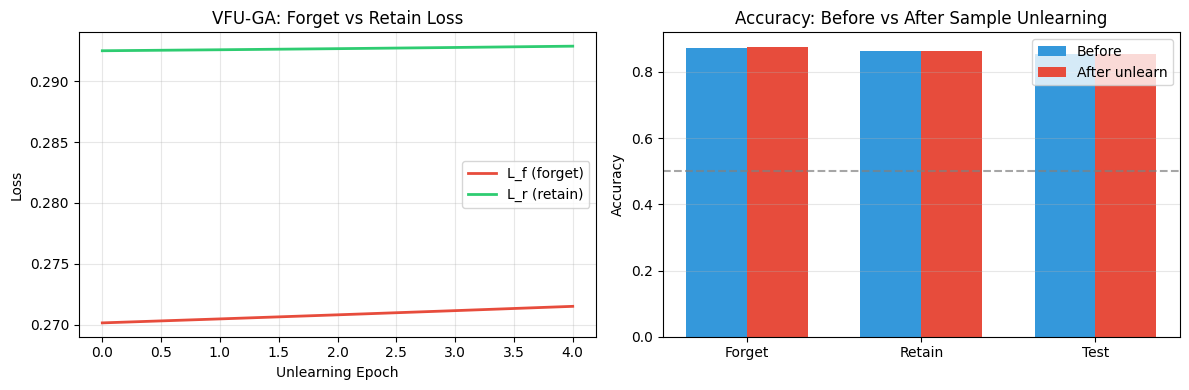

In [19]:
# VFU-GA: loss curves and metric comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(ga_history['L_f'], label='L_f (forget)', color='#e74c3c', linewidth=2)
axes[0].plot(ga_history['L_r'], label='L_r (retain)', color='#2ecc71', linewidth=2)
axes[0].set_xlabel("Unlearning Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("VFU-GA: Forget vs Retain Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Bar chart: forget / retain / test accuracy before vs after
sets = ['Forget', 'Retain', 'Test']
before_acc = [forget_metrics_before['accuracy'], retain_metrics_before['accuracy'], test_metrics_before_ga['accuracy']]
after_acc = [forget_metrics_after['accuracy'], retain_metrics_after['accuracy'], test_metrics_after_ga['accuracy']]
x = np.arange(len(sets))
w = 0.35
axes[1].bar(x - w/2, before_acc, w, label='Before', color='#3498db')
axes[1].bar(x + w/2, after_acc, w, label='After unlearn', color='#e74c3c')
axes[1].set_xticks(x)
axes[1].set_xticklabels(sets)
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy: Before vs After Sample Unlearning")
axes[1].legend()
axes[1].axhline(0.5, color='gray', linestyle='--', alpha=0.7, label='Random')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Algorithm 5: Feature Entanglement Analysis via Jacobian-Based Influence Matrix

Pre-unlearning diagnostic: for each remaining party P_j, compute the cross-party Jacobian ∂h_j^(l)/∂X_k, perform low-rank SVD, and derive the ρ metric (ratio of dominant singular value to Frobenius norm). ρ→1 means concentrated entanglement; ρ→0 means negligible coupling. Classify risk as LOW (<0.15), MEDIUM (0.15–0.40), or HIGH (≥0.40).

In [20]:
def _forward_to_layer(model, x, layer_idx):
    """Forward through a BottomModel up to (and including) the layer_idx-th sub-block."""
    children = list(model.network.children())
    linears = []
    for i, child in enumerate(children):
        if isinstance(child, nn.Linear):
            linears.append(i)
    end = linears[layer_idx] + 2 if layer_idx < len(linears) - 1 else len(children)
    end = min(end, len(children))
    sub = nn.Sequential(*children[:end])
    return sub(x)


def compute_cross_party_jacobian(vfl_model, X_parties_batch, party_k_idx, party_j_idx):
    """
    Compute cross-party influence Jacobian J_{k→j} of shape (d_ej, d_xk).
    J[d, f] = mean_over_batch( ∂²ŷ / (∂e_j[d] · ∂X_k[f]) )

    This is the mixed Hessian: how changing X_k alters the gradient signal ∂ŷ/∂e_j
    flowing to party j's embedding. The coupling arises through the top model's
    nonlinearity — changing X_k changes e_k, which changes the ReLU activation
    pattern in the top model, which changes ∂ŷ/∂e_j.

    ρ → 1: the coupling is concentrated in one direction (high entanglement).
    ρ → 0: the coupling is diffuse or negligible (low entanglement).
    """
    n_parties = vfl_model.n_parties
    for m in vfl_model.bottom_models:
        m.eval()
    vfl_model.top_model.eval()

    X_k = X_parties_batch[party_k_idx].detach().requires_grad_(True)

    embeddings = []
    e_j_leaf = None
    for i in range(n_parties):
        if i == party_k_idx:
            emb = vfl_model.bottom_models[i](X_k)
        elif i == party_j_idx:
            with torch.no_grad():
                emb_raw = vfl_model.bottom_models[i](X_parties_batch[i])
            emb = emb_raw.detach().requires_grad_(True)
            e_j_leaf = emb
        else:
            with torch.no_grad():
                emb = vfl_model.bottom_models[i](X_parties_batch[i])
        embeddings.append(emb)

    combined = torch.cat(embeddings, dim=1)
    output = vfl_model.top_model(combined)

    # ∂ŷ/∂e_j with create_graph so we can differentiate again w.r.t. X_k
    grad_e_j = torch.autograd.grad(output.sum(), e_j_leaf, create_graph=True, retain_graph=True)[0]

    d_ej = e_j_leaf.shape[1]
    d_xk = X_k.shape[1]
    J = torch.zeros(d_ej, d_xk, device=X_k.device)

    for d in range(d_ej):
        # ∂(∂ŷ/∂e_j[d]) / ∂X_k — mixed second derivative
        grad2 = torch.autograd.grad(grad_e_j[:, d].sum(), X_k, retain_graph=True)[0]
        J[d] = grad2.mean(dim=0)

    return J.detach()


def feature_entanglement_analysis(vfl_model, X_train_parties, target_party_k, svd_rank=10,
                                   tau_low=0.15, tau_high=0.40, n_batches=5, batch_size=512,
                                   device='cpu'):
    """
    Algorithm 5: Feature Entanglement Analysis via Jacobian-Based Influence Matrix.
    For each remaining party P_j, computes the cross-party mixed Hessian J_{k→j},
    performs SVD, and derives the ρ metric. Classifies risk as LOW/MEDIUM/HIGH.
    """
    k = target_party_k
    if vfl_model.party_data[k]['is_active']:
        raise ValueError("Cannot analyze entanglement for the active party. Target must be a passive party.")
    n_parties = vfl_model.n_parties
    remaining = [j for j in range(n_parties) if j != k]
    influence = {}
    risk = {}

    for j in remaining:
        J_accum = None
        for b in range(n_batches):
            start = b * batch_size
            end = min(start + batch_size, X_train_parties[k].shape[0])
            if start >= end:
                break
            X_batch = [X_train_parties[i][start:end] for i in range(n_parties)]

            J_b = compute_cross_party_jacobian(vfl_model, X_batch, k, j)
            if J_accum is None:
                J_accum = J_b
            else:
                J_accum = J_accum + J_b
        J_accum = J_accum / n_batches

        r = min(svd_rank, *J_accum.shape)
        _, S, _ = torch.linalg.svd(J_accum, full_matrices=False)
        S_top = S[:r]
        frobenius = torch.sqrt((S_top ** 2).sum())
        rho = (S_top[0] / frobenius).item() if frobenius > 1e-12 else 0.0

        influence[j] = rho

        if rho < tau_low:
            risk[j] = 'LOW'
        elif rho < tau_high:
            risk[j] = 'MEDIUM'
        else:
            risk[j] = 'HIGH'

    return influence, risk

Running Algorithm 5: Feature Entanglement Analysis...
Target party P_1 requesting unlearning

ENTANGLEMENT ANALYSIS REPORT
Party      ρ (influence)      Risk Level  
-------------------------------------------------------
P_0        0.9911             HIGH         ✗
P_2        0.9689             HIGH         ✗
P_3        0.9970             HIGH         ✗
Thresholds: LOW < 0.15, MEDIUM < 0.4, HIGH >= 0.4


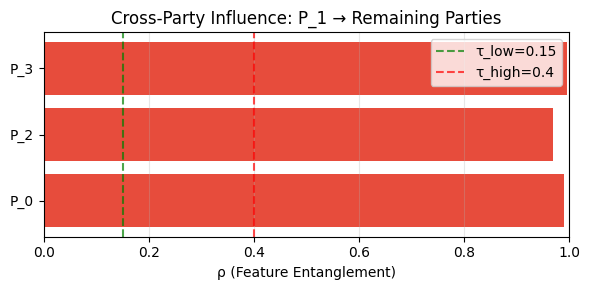

In [21]:
# Run Algorithm 5: Feature Entanglement Analysis before unlearning party 1
TARGET_K = 1  # party requesting unlearning
SVD_RANK = 10
TAU_LOW, TAU_HIGH = 0.15, 0.40
N_BATCHES = 5

print("Running Algorithm 5: Feature Entanglement Analysis...")
print(f"Target party P_{TARGET_K} requesting unlearning\n")

influence, risk = feature_entanglement_analysis(
    vfl_model_adult, X_train, TARGET_K,
    svd_rank=SVD_RANK, tau_low=TAU_LOW, tau_high=TAU_HIGH,
    n_batches=N_BATCHES, batch_size=512, device=device
)

print("=" * 55)
print("ENTANGLEMENT ANALYSIS REPORT")
print("=" * 55)
print(f"{'Party':<10} {'ρ (influence)':<18} {'Risk Level':<12}")
print("-" * 55)
for j in sorted(influence.keys()):
    rho_val = influence[j]
    r_level = risk[j]
    marker = "✓" if r_level == 'LOW' else ("⚠" if r_level == 'MEDIUM' else "✗")
    print(f"P_{j:<8} {rho_val:<18.4f} {r_level:<12} {marker}")
print("=" * 55)
print(f"Thresholds: LOW < {TAU_LOW}, MEDIUM < {TAU_HIGH}, HIGH >= {TAU_HIGH}")

# Visualize influence
fig, ax = plt.subplots(figsize=(6, 3))
parties = [f"P_{j}" for j in sorted(influence.keys())]
rhos = [influence[j] for j in sorted(influence.keys())]
colors = ['#2ecc71' if risk[j] == 'LOW' else '#f39c12' if risk[j] == 'MEDIUM' else '#e74c3c'
          for j in sorted(influence.keys())]
ax.barh(parties, rhos, color=colors)
ax.axvline(TAU_LOW, color='green', linestyle='--', alpha=0.7, label=f'τ_low={TAU_LOW}')
ax.axvline(TAU_HIGH, color='red', linestyle='--', alpha=0.7, label=f'τ_high={TAU_HIGH}')
ax.set_xlabel("ρ (Feature Entanglement)")
ax.set_title(f"Cross-Party Influence: P_{TARGET_K} → Remaining Parties")
ax.legend()
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

### Feature-Level Entanglement Analysis

Goes beyond party-level analysis: for each individual feature of the target party P_k, compute how much removing that single feature would entangle with P_k's own encoder (intra-party ρ) and with every other party's encoder (cross-party ρ). Classifies each feature's removal risk as LOW/MEDIUM/HIGH.

In [22]:
def feature_level_entanglement_analysis(vfl_model, X_train_parties, target_party_k,
                                         svd_rank=10, tau_low=0.15, tau_high=0.40,
                                         n_batches=5, batch_size=512, device='cpu', verbose=True):
    """
    Feature-level entanglement analysis for the target passive party P_k.
    For each individual feature f in P_k, computes:
      - intra-party ρ: how f influences P_k's own encoder
      - cross-party magnitude: ||J_{k→j}[:, f]|| for each remaining party j
        (column norm of the cross-party Jacobian for that feature)
      - overall risk: based on the feature's relative influence
    Returns a list of per-feature result dicts and risk classification.
    """
    k = target_party_k
    if vfl_model.party_data[k]['is_active']:
        raise ValueError("Target must be a passive party.")
    n_parties = vfl_model.n_parties
    n_features_k = X_train_parties[k].shape[1]
    feature_names = vfl_model.party_data[k].get('features', [f"f{i}" for i in range(n_features_k)])
    remaining = [j for j in range(n_parties) if j != k]

    # Step 1: Compute full cross-party Jacobians J_{k→j} for each remaining party
    cross_jacobians = {}
    for j in remaining:
        J_accum = None
        for b in range(n_batches):
            start = b * batch_size
            end = min(start + batch_size, X_train_parties[k].shape[0])
            if start >= end:
                break
            X_batch = [X_train_parties[i][start:end] for i in range(n_parties)]
            J_b = compute_cross_party_jacobian(vfl_model, X_batch, k, j)
            if J_accum is None:
                J_accum = J_b
            else:
                J_accum = J_accum + J_b
        cross_jacobians[j] = J_accum / n_batches

    # Step 2: Per-feature analysis
    results = []
    for f_idx in range(n_features_k):
        feat_name = feature_names[f_idx] if f_idx < len(feature_names) else f"f{f_idx}"

        # Intra-party: ∂h_k^(l) / ∂feature[f_idx]
        rho_intra_list = _compute_intra_jacobian_rho(
            vfl_model.bottom_models[k], X_train_parties[k], [f_idx], svd_rank, batch_size, device
        )
        rho_self = float(np.median(rho_intra_list)) if rho_intra_list else 0.0

        # Cross-party: column norm of J_{k→j}[:, f_idx] relative to full Frobenius norm
        # High ratio = this feature contributes disproportionately to the coupling with party j
        rho_cross = {}
        for j in remaining:
            J = cross_jacobians[j]
            col = J[:, f_idx]
            col_norm = torch.sqrt((col ** 2).sum()).item()
            full_frob = torch.sqrt((J ** 2).sum()).item()
            rho_cross[j] = col_norm / full_frob if full_frob > 1e-12 else 0.0

        # Overall: aggregate intra + cross
        all_scores = [rho_self] + [rho_cross[j] for j in remaining]
        rho_overall = float(np.median(all_scores))

        risk_label = _classify_risk(rho_overall, tau_low, tau_high)

        results.append({
            'feature_idx': f_idx,
            'feature_name': feat_name,
            'rho_self': rho_self,
            'rho_cross': rho_cross,
            'rho_overall': rho_overall,
            'risk': risk_label
        })

        if verbose:
            cross_str = ", ".join([f"P_{j}:{rho_cross[j]:.3f}" for j in remaining])
            print(f"  Feature {f_idx} ({feat_name}): ρ_self={rho_self:.3f}, cross=[{cross_str}], "
                  f"ρ_overall={rho_overall:.3f} → {risk_label}")

    return results

In [23]:
# Run Feature-Level Entanglement Analysis for party P_1
TARGET_K_FEAT = 1

print(f"Feature-Level Entanglement Analysis for P_{TARGET_K_FEAT}")
print(f"Features held by P_{TARGET_K_FEAT}: {vfl_model_adult.party_data[TARGET_K_FEAT]['features']}")
print("=" * 75)

feat_results = feature_level_entanglement_analysis(
    vfl_model_adult, X_train, TARGET_K_FEAT,
    svd_rank=SVD_RANK, tau_low=TAU_LOW, tau_high=TAU_HIGH,
    n_batches=N_BATCHES, batch_size=512, device=device, verbose=True
)

# Summary table
print("\n" + "=" * 75)
print("FEATURE-LEVEL ENTANGLEMENT SUMMARY")
print("=" * 75)
print(f"{'Idx':<5} {'Feature':<20} {'ρ_self':<10} {'ρ_overall':<12} {'Risk':<8}")
print("-" * 75)
for r in feat_results:
    marker = "✓" if r['risk'] == 'LOW' else ("⚠" if r['risk'] == 'MEDIUM' else "✗")
    print(f"{r['feature_idx']:<5} {r['feature_name']:<20} {r['rho_self']:<10.4f} "
          f"{r['rho_overall']:<12.4f} {r['risk']:<8} {marker}")
print("=" * 75)

# Visualization: grouped bar chart of ρ_self and ρ_overall per feature
fig, ax = plt.subplots(figsize=(10, 4))
feat_labels = [r['feature_name'] for r in feat_results]
rho_selfs = [r['rho_self'] for r in feat_results]
rho_overalls = [r['rho_overall'] for r in feat_results]
risk_colors = ['#2ecc71' if r['risk'] == 'LOW' else '#f39c12' if r['risk'] == 'MEDIUM' else '#e74c3c'
               for r in feat_results]
x = np.arange(len(feat_labels))
w = 0.35
ax.bar(x - w/2, rho_selfs, w, label='ρ_self (intra-party)', color='#3498db', alpha=0.8)
ax.bar(x + w/2, rho_overalls, w, label='ρ_overall', color=risk_colors, edgecolor='black', linewidth=0.5)
ax.axhline(TAU_LOW, color='green', linestyle='--', alpha=0.7, label=f'τ_low={TAU_LOW}')
ax.axhline(TAU_HIGH, color='red', linestyle='--', alpha=0.7, label=f'τ_high={TAU_HIGH}')
ax.set_xticks(x)
ax.set_xticklabels(feat_labels, rotation=45, ha='right', fontsize=8)
ax.set_ylabel("ρ (Entanglement)")
ax.set_title(f"Feature-Level Entanglement: P_{TARGET_K_FEAT} Features")
ax.legend(fontsize=7, loc='upper right')
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

Feature-Level Entanglement Analysis for P_1
Features held by P_1: ['hours_per_week', 'marital_status', 'race']


NameError: name '_compute_intra_jacobian_rho' is not defined

## Algorithm 6: Entanglement-Aware Passive Party Unlearning

Extends VFU-KD (Algorithm 2) with three phases:
1. **Phase 1** — Run Algorithm 5 to diagnose entanglement and classify remaining parties into S_safe, S_monitor, S_retrain.
2. **Phase 2** — Execute standard VFU-KD passive party unlearning.
3. **Phase 3** — Monitor MEDIUM-risk parties (escalate if accuracy drops > δ); retrain HIGH-risk parties via standard VFL gradient updates (warm-started from current θ_j).

In [ ]:
def entanglement_aware_passive_unlearn(vfl_model, historical_embeddings, y_train,
                                       X_train_parties, X_test_parties, y_test,
                                       target_party_k,
                                       lr_unlearn=0.01, lambda_distill=0.3, unlearn_epochs=30,
                                       svd_rank=10, tau_low=0.15, tau_high=0.40, n_batches=5,
                                       lr_retrain=0.01, retrain_epochs=10,
                                       delta_monitor=0.05, batch_size=512,
                                       device='cpu', verbose=True):
    """
    Algorithm 6: Entanglement-Aware Passive Party Unlearning.
    Phase 1: diagnose, Phase 2: VFU-KD, Phase 3: monitor & retrain.
    """
    k = target_party_k
    if vfl_model.party_data[k]['is_active']:
        raise ValueError("Cannot unlearn the active party (label holder). Target must be a passive party.")
    n_parties = vfl_model.n_parties
    remaining = [j for j in range(n_parties) if j != k]

    # ═══ PHASE 1: Pre-Unlearning Entanglement Diagnosis ═══
    if verbose:
        print("╔══════════════════════════════════════════════════════╗")
        print("║  PHASE 1: Pre-Unlearning Entanglement Diagnosis     ║")
        print("╚══════════════════════════════════════════════════════╝")
    influence, risk_map = feature_entanglement_analysis(
        vfl_model, X_train_parties, k,
        svd_rank=svd_rank, tau_low=tau_low, tau_high=tau_high,
        n_batches=n_batches, batch_size=batch_size, device=device
    )
    S_safe, S_monitor, S_retrain = [], [], []
    for j in remaining:
        r = risk_map[j]
        if verbose:
            print(f"  Influence P_{k} → P_{j}: {influence[j]:.4f}, Risk: {r}")
        if r == 'LOW':
            S_safe.append(j)
        elif r == 'MEDIUM':
            S_monitor.append(j)
        else:
            S_retrain.append(j)
    if verbose:
        print(f"  S_safe={S_safe}, S_monitor={S_monitor}, S_retrain={S_retrain}\n")

    # Baseline accuracy before unlearning
    metrics_pre = evaluate_unlearned_model(
        vfl_model, vfl_model.top_model, X_test_parties, y_test,
        passive_party_u=k, device=device
    ) if False else None
    # Full model accuracy before
    acc_before = {}
    for j in remaining:
        for m in vfl_model.bottom_models:
            m.eval()
        vfl_model.top_model.eval()
        with torch.no_grad():
            out, _ = vfl_model.forward(X_test_parties)
            pred = (out > 0.5).float()
        acc_before[j] = accuracy_score(y_test.cpu().numpy(), pred.cpu().numpy())

    # ═══ PHASE 2: Execute VFU-KD (Algorithm 2) ═══
    if verbose:
        print("╔══════════════════════════════════════════════════════╗")
        print("║  PHASE 2: Execute VFU-KD Passive Party Unlearning   ║")
        print("╚══════════════════════════════════════════════════════╝")
    student_top, unlearn_history = vfu_kd_passive_unlearn(
        vfl_model, historical_embeddings, y_train,
        passive_party_u=k, lr_unlearn=lr_unlearn, lambda_distill=lambda_distill,
        unlearn_epochs=unlearn_epochs, device=device, verbose=verbose
    )

    # ═══ PHASE 3: Post-Unlearning Monitoring & Mitigation ═══
    if verbose:
        print("\n╔══════════════════════════════════════════════════════╗")
        print("║  PHASE 3: Post-Unlearning Monitoring & Mitigation   ║")
        print("╚══════════════════════════════════════════════════════╝")

    # Evaluate post-unlearning accuracy using student top (no P_k)
    metrics_post = evaluate_unlearned_model(
        vfl_model, student_top, X_test_parties, y_test,
        passive_party_u=k, device=device
    )
    acc_after_global = metrics_post['accuracy']

    # Monitor MEDIUM-risk parties
    for j in list(S_monitor):
        acc_drop = acc_before[j] - acc_after_global
        if verbose:
            print(f"  [MONITOR] P_{j}: acc drop = {acc_drop:.4f} (threshold δ = {delta_monitor})")
        if acc_drop > delta_monitor:
            if verbose:
                print(f"    → Escalating P_{j} to S_retrain")
            S_monitor.remove(j)
            S_retrain.append(j)

    # Retrain HIGH-risk parties
    retrained = {}
    if S_retrain:
        if verbose:
            print(f"\n  Retraining HIGH-risk parties: {S_retrain}")
        for j in S_retrain:
            bottom_j = vfl_model.bottom_models[j]
            for p in bottom_j.parameters():
                p.requires_grad = True
            opt_j = RAdam(bottom_j.parameters(), lr=lr_retrain)
            criterion = nn.BCELoss()
            n_train = y_train.shape[0]
            retained = [i for i in range(n_parties) if i != k]

            for ep in range(retrain_epochs):
                bottom_j.train()
                student_top.eval()
                perm = np.random.permutation(n_train)
                ep_loss = 0.0
                nb = 0
                for start in range(0, n_train, batch_size):
                    end = min(start + batch_size, n_train)
                    idx = perm[start:end]
                    X_batch = [X_train_parties[i][idx] for i in range(n_parties)]
                    y_batch = y_train[idx]
                    embs = []
                    for i in retained:
                        if i == j:
                            embs.append(vfl_model.bottom_models[i](X_batch[i]))
                        else:
                            with torch.no_grad():
                                embs.append(vfl_model.bottom_models[i](X_batch[i]))
                    combined = torch.cat(embs, dim=1)
                    out = student_top(combined)
                    loss = criterion(out, y_batch)
                    opt_j.zero_grad()
                    loss.backward()
                    opt_j.step()
                    ep_loss += loss.item()
                    nb += 1
                if verbose and (ep + 1) % 5 == 0:
                    print(f"    P_{j} retrain epoch {ep+1}/{retrain_epochs} - loss: {ep_loss/nb:.4f}")
            retrained[j] = True

    # Final metrics
    final_metrics = evaluate_unlearned_model(
        vfl_model, student_top, X_test_parties, y_test,
        passive_party_u=k, device=device
    )
    if verbose:
        print(f"\n  Final metrics after entanglement-aware unlearning:")
        for m, v in final_metrics.items():
            print(f"    {m}: {v:.4f}")

    return student_top, influence, risk_map, final_metrics, unlearn_history

In [ ]:
# Run Algorithm 6: Entanglement-Aware Passive Party Unlearning
# First re-create a fresh VFL model and retrain (VFU-KD passive unlearn modifies the top model)
print("Re-initializing VFL model for Algorithm 6 demonstration...\n")
vfl_model_alg6 = VFLModel(adult_parties, embedding_dim=32, device=device)
trainer_alg6 = VFLTrainer(vfl_model_alg6, learning_rate=1e-2)
X_train_a6, X_test_a6, y_train_a6, y_test_a6, _ = trainer_alg6.prepare_data(adult_parties, test_size=0.2)
history_a6, hist_emb_a6 = trainer_alg6.train_with_embedding_history(
    X_train_a6, X_test_a6, y_train_a6, y_test_a6,
    epochs=50, batch_size=512, lr_active=1e-2, lr_passive=1e-2, verbose=False
)
pre_metrics = trainer_alg6.evaluate(X_test_a6, y_test_a6)
print(f"Pre-unlearning metrics: Acc={pre_metrics['accuracy']:.4f}, F1={pre_metrics['f1']:.4f}, AUC={pre_metrics['auc']:.4f}\n")

student_top_a6, infl_a6, risk_a6, final_a6, ul_hist_a6 = entanglement_aware_passive_unlearn(
    vfl_model_alg6, hist_emb_a6, y_train_a6,
    X_train_a6, X_test_a6, y_test_a6,
    target_party_k=1,
    lr_unlearn=1e-2, lambda_distill=0.3, unlearn_epochs=30,
    svd_rank=10, tau_low=0.15, tau_high=0.40, n_batches=5,
    lr_retrain=1e-2, retrain_epochs=10, delta_monitor=0.05,
    batch_size=512, device=device, verbose=True
)

# Comparison table
print("\n" + "=" * 60)
print("Algorithm 6: BEFORE vs AFTER Comparison")
print("=" * 60)
print(f"{'Metric':<12} {'Before':<15} {'After (Alg 6)':<15} {'Δ':<10}")
print("-" * 60)
for key in ['accuracy', 'f1', 'auc']:
    b, a = pre_metrics[key], final_a6[key]
    print(f"{key:<12} {b:<15.4f} {a:<15.4f} {a-b:+.4f}")
print("=" * 60)

Re-initializing VFL model for Algorithm 6 demonstration...

Pre-unlearning metrics: Acc=0.8579, F1=0.6932, AUC=0.9115

╔══════════════════════════════════════════════════════╗
║  PHASE 1: Pre-Unlearning Entanglement Diagnosis     ║
╚══════════════════════════════════════════════════════╝
  Influence P_1 → P_0: 0.9931, Risk: HIGH
  Influence P_1 → P_2: 0.9942, Risk: HIGH
  Influence P_1 → P_3: 0.9992, Risk: HIGH
  S_safe=[], S_monitor=[], S_retrain=[0, 2, 3]

╔══════════════════════════════════════════════════════╗
║  PHASE 2: Execute VFU-KD Passive Party Unlearning   ║
╚══════════════════════════════════════════════════════╝
Unlearn Epoch 10/30 - Loss: 0.2541 (L_pred: 0.3468, L_dist: 0.0377)
Unlearn Epoch 20/30 - Loss: 0.2493 (L_pred: 0.3415, L_dist: 0.0341)
Unlearn Epoch 30/30 - Loss: 0.2458 (L_pred: 0.3376, L_dist: 0.0317)

╔══════════════════════════════════════════════════════╗
║  PHASE 3: Post-Unlearning Monitoring & Mitigation   ║
╚════════════════════════════════════════════════

## Algorithm 7: Entanglement-Aware Feature Unlearning

Extends VFU-KD Feature Unlearning (Algorithm 3) with entanglement analysis:
1. **Phase 1** — Intra-party analysis (how target features F_k affect P_k's own encoder), cross-party analysis (how F_k affects other parties), and active model analysis.
2. **Phase 2** — Risk classification and impact report.
3. **Phase 3** — Execute standard VFU-KD feature unlearning.
4. **Phase 4** — If active model is HIGH risk, adapt θ_a via knowledge distillation with the new reduced embeddings.

In [ ]:
def _compute_intra_jacobian_rho(model, X_full, feature_indices, svd_rank, batch_size, device):
    """Compute ρ for the intra-party Jacobian ∂h^(l)/∂F_k for each layer of a bottom model."""
    model.eval()
    children = list(model.network.children())
    n_layers = sum(1 for c in children if isinstance(c, nn.Linear))
    rho_list = []
    n_use = min(X_full.shape[0], batch_size)
    X = X_full[:n_use].detach().requires_grad_(True)

    for l in range(n_layers):
        h = _forward_to_layer(model, X, l)
        d_h = h.shape[1]
        d_f = len(feature_indices)
        J = torch.zeros(d_h, d_f, device=device)
        for i in range(d_h):
            g = torch.autograd.grad(h[:, i].sum(), X, create_graph=False, retain_graph=True)[0]
            for fi_idx, fi in enumerate(feature_indices):
                J[i, fi_idx] = g[:, fi].mean()

        r = min(svd_rank, *J.shape)
        _, S, _ = torch.linalg.svd(J, full_matrices=False)
        S_top = S[:r]
        frob = torch.sqrt((S_top ** 2).sum())
        rho = (S_top[0] / frob).item() if frob > 1e-12 else 0.0
        rho_list.append(rho)
    return rho_list


def _classify_risk(rho, tau_low, tau_high):
    if rho < tau_low:
        return 'LOW'
    elif rho < tau_high:
        return 'MEDIUM'
    return 'HIGH'


def entanglement_aware_feature_unlearn(vfl_model, X_train_parties, X_test_parties, y_train, y_test,
                                        historical_embeddings,
                                        target_party_k, feature_indices_to_forget,
                                        lr_feature=0.01, feature_unlearn_epochs=30,
                                        lr_adapt=0.01, lambda_distill=0.3, adapt_epochs=5,
                                        svd_rank=10, tau_low=0.15, tau_high=0.40, n_batches=5,
                                        batch_size=512, device='cpu', verbose=True):
    """
    Algorithm 7: Entanglement-Aware Feature Unlearning.
    Phase 1: intra-party, cross-party, active model diagnosis.
    Phase 2: risk classification.
    Phase 3: VFU-KD feature unlearning.
    Phase 4: active model adaptation if HIGH risk.
    """
    k = target_party_k
    if vfl_model.party_data[k]['is_active']:
        raise ValueError("Cannot unlearn features from the active party. Target must be a passive party.")
    F_k = sorted(set(feature_indices_to_forget))
    n_parties = vfl_model.n_parties
    remaining = [j for j in range(n_parties) if j != k]

    # ═══ PHASE 1: Feature-Level Entanglement Diagnosis ═══
    if verbose:
        print("╔══════════════════════════════════════════════════════╗")
        print("║  PHASE 1: Feature-Level Entanglement Diagnosis      ║")
        print("╚══════════════════════════════════════════════════════╝")

    # 1a. Intra-party: ∂h_k^(l) / ∂F_k
    rho_intra_list = _compute_intra_jacobian_rho(
        vfl_model.bottom_models[k], X_train_parties[k], F_k, svd_rank, batch_size, device
    )
    rho_self = float(np.median(rho_intra_list))
    risk_self = _classify_risk(rho_self, tau_low, tau_high)
    if verbose:
        print(f"  Self-impact (P_{k} encoder): ρ = {rho_self:.4f}, Risk = {risk_self}")

    # 1b. Cross-party: mixed Hessian restricted to target features F_k
    I_feat = {}
    risk_cross = {}
    for j in remaining:
        J_accum = None
        for b in range(n_batches):
            start = b * batch_size
            end = min(start + batch_size, X_train_parties[k].shape[0])
            if start >= end:
                break
            X_batch = [X_train_parties[i][start:end] for i in range(n_parties)]
            J_b = compute_cross_party_jacobian(vfl_model, X_batch, k, j)
            J_b_feat = J_b[:, F_k]
            if J_accum is None:
                J_accum = J_b_feat
            else:
                J_accum = J_accum + J_b_feat
        J_accum = J_accum / n_batches
        r = min(svd_rank, *J_accum.shape)
        _, S, _ = torch.linalg.svd(J_accum, full_matrices=False)
        S_top = S[:r]
        frob = torch.sqrt((S_top ** 2).sum())
        rho = (S_top[0] / frob).item() if frob > 1e-12 else 0.0
        I_feat[j] = rho
        risk_cross[j] = _classify_risk(rho, tau_low, tau_high)
        if verbose:
            print(f"  Cross-party P_{j} impact: ρ = {rho:.4f}, Risk = {risk_cross[j]}")

    # 1c. Active model analysis: ∂h_a^(l) / ∂e_k (using stored embeddings)
    top_model = vfl_model.top_model
    top_model.eval()
    last_emb = historical_embeddings[-1]
    E_full = torch.cat(last_emb, dim=1).to(device)
    n_use = min(E_full.shape[0], batch_size)
    E_batch = E_full[:n_use].detach().requires_grad_(True)

    top_children = list(top_model.network.children())
    n_top_layers = sum(1 for c in top_children if isinstance(c, nn.Linear))
    rho_active_list = []
    emb_dim = vfl_model.embedding_dim
    e_k_start = k * emb_dim
    e_k_end = e_k_start + emb_dim

    for l in range(n_top_layers):
        linears_seen = 0
        end_idx = 0
        for ci, child in enumerate(top_children):
            if isinstance(child, nn.Linear):
                linears_seen += 1
            if linears_seen > l:
                end_idx = ci + 2 if ci + 2 <= len(top_children) else len(top_children)
                break
        sub = nn.Sequential(*top_children[:end_idx])
        h_a = sub(E_batch)
        d_h = h_a.shape[1] if h_a.dim() > 1 else 1
        if h_a.dim() == 1:
            h_a = h_a.unsqueeze(1)
        J_active = torch.zeros(d_h, emb_dim, device=device)
        for i in range(d_h):
            g = torch.autograd.grad(h_a[:, i].sum(), E_batch, create_graph=False, retain_graph=True)[0]
            J_active[i] = g[:, e_k_start:e_k_end].mean(dim=0)
        r = min(svd_rank, *J_active.shape)
        _, S, _ = torch.linalg.svd(J_active, full_matrices=False)
        S_top = S[:r]
        frob = torch.sqrt((S_top ** 2).sum())
        rho = (S_top[0] / frob).item() if frob > 1e-12 else 0.0
        rho_active_list.append(rho)
    I_active = float(np.median(rho_active_list))
    risk_active = _classify_risk(I_active, tau_low, tau_high)
    if verbose:
        print(f"  Active model impact: ρ = {I_active:.4f}, Risk = {risk_active}")

    # ═══ PHASE 2: Risk Classification ═══
    if verbose:
        print("\n╔══════════════════════════════════════════════════════╗")
        print("║  PHASE 2: Risk Classification & Decision            ║")
        print("╚══════════════════════════════════════════════════════╝")
        print(f"  Self: {risk_self}  |  Active: {risk_active}  |  Cross: {risk_cross}")

    # ═══ PHASE 3: Execute VFU-KD Feature Unlearning (Algorithm 3) ═══
    if verbose:
        print("\n╔══════════════════════════════════════════════════════╗")
        print("║  PHASE 3: Execute VFU-KD Feature Unlearning         ║")
        print("╚══════════════════════════════════════════════════════╝")
    student_bottom, feat_hist, retained_idx = vfu_kd_feature_unlearn(
        vfl_model, X_train_parties[k], F_k, k,
        lr=lr_feature, unlearn_epochs=feature_unlearn_epochs,
        batch_size=batch_size, device=device, verbose=verbose
    )

    # ═══ PHASE 4: Active Model Adaptation (if needed) ═══
    adapted_top = None
    if risk_active == 'HIGH':
        if verbose:
            print("\n╔══════════════════════════════════════════════════════╗")
            print("║  PHASE 4: Active Model Adaptation (HIGH risk)       ║")
            print("╚══════════════════════════════════════════════════════╝")
        teacher_top = vfl_model.top_model
        for p in teacher_top.parameters():
            p.requires_grad = False

        new_emb_dim = vfl_model.embedding_dim  # same embedding dim, just from student bottom
        new_top_input = vfl_model.embedding_dim * n_parties  # same dim (student produces same size embedding)
        adapted_top = TopModel(new_top_input, hidden_dim=32, output_dim=1).to(device)
        opt_adapt = RAdam(adapted_top.parameters(), lr=lr_adapt)
        criterion = nn.BCELoss()

        n_train = y_train.shape[0]
        T = len(historical_embeddings)
        for ep in range(adapt_epochs):
            adapted_top.train()
            ep_loss = 0.0
            for s in range(T):
                E_s = historical_embeddings[s]
                # Replace E_k^t with new embeddings from student bottom
                with torch.no_grad():
                    e_k_new = student_bottom(X_train_parties[k][:, retained_idx])
                E_new = [E_s[i] if i != k else e_k_new for i in range(n_parties)]
                E_retain_cat = torch.cat(E_new, dim=1)
                E_full_cat = torch.cat(E_s, dim=1)
                with torch.no_grad():
                    y_T = teacher_top(E_full_cat)
                y_S = adapted_top(E_retain_cat)
                eps_v = 1e-7
                y_s_c = y_S.clamp(eps_v, 1 - eps_v)
                y_t_c = y_T.clamp(eps_v, 1 - eps_v)
                log_p_s = torch.stack([torch.log(1 - y_s_c), torch.log(y_s_c)], dim=1)
                p_t = torch.stack([1 - y_t_c, y_t_c], dim=1)
                L_pred = criterion(y_S, y_train)
                L_dist = F.kl_div(log_p_s, p_t, reduction='batchmean')
                loss = (1 - lambda_distill) * L_pred + lambda_distill * L_dist
                opt_adapt.zero_grad()
                loss.backward()
                opt_adapt.step()
                ep_loss += loss.item()
            if verbose and (ep + 1) % 2 == 0:
                print(f"  Adapt epoch {ep+1}/{adapt_epochs} - loss: {ep_loss/T:.4f}")
        vfl_model.top_model = adapted_top
    else:
        if verbose:
            print(f"\n  Active model risk is {risk_active} — no adaptation needed.")

    # Final evaluation
    X_test_reduced = X_test_parties[k][:, retained_idx]
    final_metrics = evaluate_vfl_with_party_bottom_replaced(
        vfl_model, X_test_parties, y_test, k, student_bottom, X_test_reduced, device
    )

    report = {
        'rho_self': rho_self, 'risk_self': risk_self,
        'I_active': I_active, 'risk_active': risk_active,
        'I_feat': I_feat, 'risk_cross': risk_cross,
        'final_metrics': final_metrics
    }
    return student_bottom, adapted_top, report

In [ ]:
# Run Algorithm 7: Entanglement-Aware Feature Unlearning
print("Re-initializing VFL model for Algorithm 7 demonstration...\n")
vfl_model_alg7 = VFLModel(adult_parties, embedding_dim=32, device=device)
trainer_alg7 = VFLTrainer(vfl_model_alg7, learning_rate=1e-2)
X_train_a7, X_test_a7, y_train_a7, y_test_a7, _ = trainer_alg7.prepare_data(adult_parties, test_size=0.2)
history_a7, hist_emb_a7 = trainer_alg7.train_with_embedding_history(
    X_train_a7, X_test_a7, y_train_a7, y_test_a7,
    epochs=50, batch_size=512, lr_active=1e-2, lr_passive=1e-2, verbose=False
)
pre_a7 = trainer_alg7.evaluate(X_test_a7, y_test_a7)
print(f"Pre-unlearning metrics: Acc={pre_a7['accuracy']:.4f}, F1={pre_a7['f1']:.4f}, AUC={pre_a7['auc']:.4f}\n")

TARGET_K_7 = 1
FEATURES_TO_FORGET_7 = [0, 1]

student_bot_a7, adapted_top_a7, report_a7 = entanglement_aware_feature_unlearn(
    vfl_model_alg7, X_train_a7, X_test_a7, y_train_a7, y_test_a7,
    hist_emb_a7,
    target_party_k=TARGET_K_7, feature_indices_to_forget=FEATURES_TO_FORGET_7,
    lr_feature=1e-2, feature_unlearn_epochs=30,
    lr_adapt=1e-2, lambda_distill=0.3, adapt_epochs=5,
    svd_rank=10, tau_low=0.15, tau_high=0.40, n_batches=5,
    batch_size=512, device=device, verbose=True
)

# Impact report summary
print("\n" + "=" * 60)
print("ALGORITHM 7: IMPACT REPORT")
print("=" * 60)
print(f"Self-impact (P_{TARGET_K_7}): ρ = {report_a7['rho_self']:.4f}, Risk = {report_a7['risk_self']}")
print(f"Active model impact:  ρ = {report_a7['I_active']:.4f}, Risk = {report_a7['risk_active']}")
for j, rho_v in report_a7['I_feat'].items():
    print(f"Cross-party P_{j}:    ρ = {rho_v:.4f}, Risk = {report_a7['risk_cross'][j]}")
print("-" * 60)
print(f"{'Metric':<12} {'Before':<15} {'After (Alg 7)':<15} {'Δ':<10}")
print("-" * 60)
for key in ['accuracy', 'f1', 'auc']:
    b, a = pre_a7[key], report_a7['final_metrics'][key]
    print(f"{key:<12} {b:<15.4f} {a:<15.4f} {a-b:+.4f}")
print("=" * 60)

Re-initializing VFL model for Algorithm 7 demonstration...

Pre-unlearning metrics: Acc=0.8530, F1=0.6740, AUC=0.9096

╔══════════════════════════════════════════════════════╗
║  PHASE 1: Feature-Level Entanglement Diagnosis      ║
╚══════════════════════════════════════════════════════╝
  Self-impact (P_1 encoder): ρ = 0.7912, Risk = HIGH
  Cross-party P_0 impact: ρ = 0.9973, Risk = HIGH
  Cross-party P_2 impact: ρ = 0.9980, Risk = HIGH
  Cross-party P_3 impact: ρ = 0.9986, Risk = HIGH
  Active model impact: ρ = 0.8685, Risk = HIGH

╔══════════════════════════════════════════════════════╗
║  PHASE 2: Risk Classification & Decision            ║
╚══════════════════════════════════════════════════════╝
  Self: HIGH  |  Active: HIGH  |  Cross: {0: 'HIGH', 2: 'HIGH', 3: 'HIGH'}

╔══════════════════════════════════════════════════════╗
║  PHASE 3: Execute VFU-KD Feature Unlearning         ║
╚══════════════════════════════════════════════════════╝
Feature Unlearn Epoch 10/30 - KL loss: 0.054